# BÁO CÁO THỰC NGHIỆM NỘI DUNG 2: AGGREGATION SKEW & SALTING OPTIMIZATION
**Đề tài:** Tối ưu hóa Pipeline Xử lý Lệch tải Không gian trên Apache Spark và Đánh giá Mật độ Trả khách quanh Ranh giới Thu phí Manhattan (Dữ liệu NYC HVFHV 2026)  
**Phần phụ trách:** Chương 3 (Mục 3.1 & 3.2: Thiết kế Giải thuật Phép gom nhóm) và Chương 4 (Mục 4.2: Đánh giá Hiệu năng Aggregation Skew)  
**Tác giả:** Nhóm nghiên cứu Big Data Pipeline  
**Công nghệ mục tiêu:** Spark 3.5.9 theo Compose; host `requirements.txt` hiện pin PySpark 3.5.6 và cần được đồng bộ trước benchmark chính thức; DuckDB 1.5.6

---

## TỔNG QUAN NỘI DUNG 2
Nội dung này tập trung độc lập vào khảo sát hiện tượng lệch tải (skew) trong phép toán gom nhóm tổng hợp `groupBy()` theo mã vùng đón khách `PULocationID`.

### Phạm vi 3 phương án so sánh:
1. **Phương án 1 (Baseline GroupBy):** Tổng hợp trực tiếp theo `PULocationID`.
2. **Phương án 2 (Uniform Salting):** Phân chia đều dữ liệu theo $S=8$ bucket salt cho toàn bộ các khóa, thực hiện Two-Stage Aggregation.
3. **Phương án 3 (Selective Salting):** Chỉ phân chia $S=8$ bucket salt cho **14 Hotspot Pickup P95** được nhận diện từ tầng Silver; các khóa bình thường giữ nguyên salt = 0, thực hiện Two-Stage Aggregation.

> [!NOTE]
> **Định nghĩa phép tổng hợp trên mỗi `PULocationID`:**
> - `trip_count`: Tổng số chuyến xe ($\sum 1$).
> - `avg_fare`: Cước trung bình $\frac{\sum \text{base\_passenger\_fare}}{\sum \text{non-null fare count}}$ (bảo toàn mẫu số chính xác).
> - `total_miles`: Tổng quãng đường ($\sum \text{trip\_miles}$).

> [!IMPORTANT]
> **Cơ chế Spark Catalyst:** Phép `groupBy()` trong Spark áp dụng cơ chế Map-side Partial Aggregation (`HashAggregate`) trước khi Shuffle. Do đó, skew tự nhiên của dữ liệu thô không đồng nghĩa Salting sẽ cải thiện thời gian chạy. Toàn bộ nhận định phải được kiểm chứng bằng số đo Task Duration, Task Skew Ratio (TSR) và đối soát độc lập với DuckDB.


## Saved-output provenance

The outputs already stored in this notebook are historical local-functional evidence: the recorded Spark master is `local[4]`. Do not cite those timings as multi-worker Standalone results. Full mode now requires Spark 3.5.9 and active executors on at least two worker hosts; outputs are written to the `official_standalone` tier only after those checks pass.

## 1. Cấu hình Môi trường & Khởi tạo Metric Collector
Cấu hình JVM Java 17, đồng bộ môi trường Python worker và khởi tạo collector theo dõi qua Spark REST API.

In [41]:
import os
import sys
import time
import json
import urllib.request
import statistics
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from pyspark.sql import functions as F

# Bổ sung thư mục gốc vào path để import module hỗ trợ
sys.path.insert(0, os.path.abspath(".."))
from scripts.chapter_03.benchmark_engine import (
    configure_environment,
    resolve_paths,
    dataset_manifest_fingerprint,
    get_spark_master_url,
    create_benchmark_spark_session,
    SparkMetricsCollector,
    load_hotspot_pu_ids,
    aggregate_baseline,
    aggregate_uniform_salting,
    aggregate_selective_salting,
    verify_aggregation_with_duckdb,
    verify_distributed_executors,
    write_csv_preserving_history,
)

# Kích hoạt cấu hình môi trường chuẩn
configure_environment()
paths = resolve_paths()

print(">>> Cấu hình đường dẫn hệ thống:")
for k, v in paths.items():
    print(f"  - {k}: {v}")


>>> Cấu hình đường dẫn hệ thống:
  - in_container: False
  - base_dir: /home/kedora/SEM5/Bigdata/taxi-data-baker-
  - base_data: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data
  - silver_path: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/silver/fhvhv_2026_01_clean.parquet
  - hotspots_pu_path: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/silver/hotspots_p95_pu_2026_01
  - hotspots_do_path: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/silver/hotspots_p95_do_2026_01
  - zone_lookup_path: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/raw/taxi+_zone_lookup.csv
  - benchmarks_dir: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/benchmarks
  - plans_dir: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/benchmarks/nd3_plans
  - events_dir: /home/kedora/SEM5/Bigdata/taxi-data-baker-/logs/spark-events


## 2. Kiểm tra Danh sách 14 Hotspot Pickup (P95) từ Tầng Silver
Kiểm tra danh mục 14 vùng điểm nóng đón khách đã được nhận diện và tính toán từ tầng Silver (`data/silver/hotspots_p95_pu_2026_01`).

In [42]:
hotspot_pu_ids = load_hotspot_pu_ids(paths["hotspots_pu_path"])
print(f">>> Số lượng Hotspots P95 được xác nhận: {len(hotspot_pu_ids)} zones")
print(f">>> Danh sách mã vùng Hotspot: {hotspot_pu_ids}")

# Đọc chi tiết số chuyến của từng Hotspot từ tầng Silver bằng DuckDB
df_hp_detail = duckdb.query(f"""
    SELECT PULocationID, trip_count, 
           ROUND(trip_count * 100.0 / (SELECT SUM(trip_count) FROM read_parquet('{paths["hotspots_pu_path"]}/*.parquet')), 2) AS pct_among_hotspots
    FROM read_parquet('{paths["hotspots_pu_path"]}/*.parquet')
    ORDER BY trip_count DESC;
""").df()
display(df_hp_detail)


>>> Số lượng Hotspots P95 được xác nhận: 14 zones
>>> Danh sách mã vùng Hotspot: [7, 37, 61, 76, 79, 112, 132, 138, 161, 181, 230, 231, 234, 255]


,PULocationID,trip_count,pct_among_hotspots
0,138,318535,9.90
1,61,274662,8.53
2,132,266053,8.27
3,76,242839,7.54
4,37,242715,7.54
5,79,231424,7.19
6,181,211072,6.56
7,255,209451,6.51
8,230,209334,6.50
9,161,206722,6.42


## 3. Khảo sát Tính Phân bố Đều của Chiến lược Gán Salt
Chiến lược gán salt sử dụng hàm băm xác định:
$$\\text{salt} = \\operatorname{pmod}(\\operatorname{abs}(\\operatorname{hash}(\\text{pickup\\_datetime}, \\text{dropoff\\_datetime}, \\text{trip\\_miles})), S)$$
với số lượng bucket $S = 8$.

Kiểm tra phân bố của các bucket trên 14 vùng hotspot để đảm bảo mỗi bucket nhận xấp xỉ $12.5\\%$ dữ liệu.

In [43]:
salt_check_sql = f"""
WITH salted AS (
    SELECT 
        PULocationID,
        abs(hash(pickup_datetime, dropoff_datetime, trip_miles)) % 8 AS salt
    FROM read_parquet('{paths["silver_path"]}/*.parquet')
    WHERE PULocationID IN ({', '.join(map(str, hotspot_pu_ids))})
)
SELECT 
    salt,
    COUNT(*) AS records_count,
    ROUND(COUNT(*) * 100.0 / SUM(COUNT(*)) OVER (), 2) AS percentage
FROM salted
GROUP BY salt
ORDER BY salt;
"""
df_salt_dist = duckdb.query(salt_check_sql).df()
print(">>> Phân bố bucket salt trên 14 Hotspot Pickup:")
display(df_salt_dist)

assert len(df_salt_dist) == 8, "Lỗi: Không đủ 8 bucket salt!"
assert (df_salt_dist["percentage"] >= 12.0).all() and (df_salt_dist["percentage"] <= 13.0).all(),     "Cảnh báo: Phân bố salt bị lệch khỏi mức lý tưởng 12.5%!"
print(">>> ĐẠT: Chiến lược gán salt hoàn toàn đồng đều (~12.5% mỗi bucket) và tái lập 100%.")


>>> Phân bố bucket salt trên 14 Hotspot Pickup:


,salt,records_count,percentage
0,0,402032,12.49
1,1,402656,12.51
2,2,402929,12.52
3,3,401880,12.49
4,4,402959,12.52
5,5,402698,12.51
6,6,401645,12.48
7,7,402051,12.49


>>> ĐẠT: Chiến lược gán salt hoàn toàn đồng đều (~12.5% mỗi bucket) và tái lập 100%.


## 4. Khởi tạo SparkSession Chuẩn Thực nghiệm
Cấu hình shuffle partition mục tiêu là `spark.sql.shuffle.partitions = 200`. Tắt AQE (`spark.sql.adaptive.enabled = false`) nhằm cô lập chính xác hành vi của toán tử gom nhóm.

In [44]:
# Chế độ thực nghiệm: 'pilot' (kiểm tra nhanh logic) hoặc 'full' (benchmark chính thức)
BENCHMARK_MODE = os.environ.get("BENCHMARK_MODE", "full")
NUM_ITERATIONS = 1 if BENCHMARK_MODE == "pilot" else 3
SHUFFLE_PARTITIONS = 200

print(f">>> Thiết lập chế độ chạy: {BENCHMARK_MODE.upper()}")
print(f">>> Số lượt đo chính thức: {NUM_ITERATIONS}")
print(f">>> Shuffle Partitions: {SHUFFLE_PARTITIONS}")

master_url = get_spark_master_url()
print(f">>> Spark Master Target: {master_url}")
RESULT_TIER = "official_standalone" if BENCHMARK_MODE == "full" else ("local_functional" if master_url.startswith("local") else "pilot_standalone")
PLAN_DIR = os.path.join(paths["nd2_plans_dir"], RESULT_TIER)
os.makedirs(PLAN_DIR, exist_ok=True)

spark = create_benchmark_spark_session(
    app_name="02_Benchmark_Aggregation_Salting",
    master_url=master_url,
    shuffle_partitions=SHUFFLE_PARTITIONS,
    enable_aqe=False,
    require_standalone=(BENCHMARK_MODE == "full")
)

collector = SparkMetricsCollector(spark)

# Đọc tập dữ liệu Silver
df_silver = spark.read.parquet(paths["silver_path"] + "/*.parquet")
print(f">>> Tầng Silver đã sẵn sàng:")
df_silver.printSchema()


>>> Thiết lập chế độ chạy: FULL
>>> Số lượt đo chính thức: 3
>>> Shuffle Partitions: 200
>>> Spark Master Target: local[4]
>>> Tầng Silver đã sẵn sàng:
root
 |-- pickup_datetime: timestamp_ntz (nullable = true)
 |-- dropoff_datetime: timestamp_ntz (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- trip_miles: double (nullable = true)
 |-- trip_time: long (nullable = true)
 |-- base_passenger_fare: double (nullable = true)
 |-- cbd_congestion_fee: double (nullable = true)
 |-- dropoff_hour: integer (nullable = true)
 |-- time_period: string (nullable = true)



26/10/29 17:23:38 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


## 5. Phân tích Kế hoạch Thực thi Vật lý (Execution Plans)
Kiểm tra kế hoạch thực thi Catalyst để làm rõ sự khác biệt giữa Baseline và Salting:
- **Baseline:** Áp dụng `HashAggregate` cục bộ (Partial) $\to$ `Exchange hashpartitioning(PULocationID)` $\to$ `HashAggregate` toàn cục (Final). Do chỉ có $261$ zone, dữ liệu qua Shuffle Exchange bị nén triệt để!
- **Salting (Two-Stage):** Bắt buộc phải qua 2 chu kỳ gom nhóm và 2 tầng Shuffle Exchange, gia tăng chi phí CPU và điều phối task.

In [45]:
df_plan_base = aggregate_baseline(df_silver)
df_plan_uniform = aggregate_uniform_salting(df_silver, num_salts=8)
df_plan_selective = aggregate_selective_salting(df_silver, hotspot_pu_ids, num_salts=8)

print("=" * 80)
print(">>> 1. KẾ HOẠCH VẬT LÝ BASELINE GROUPBY:")
print("=" * 80)
df_plan_base.explain(mode="formatted")

print("\n" + "=" * 80)
print(">>> 2. KẾ HOẠCH VẬT LÝ UNIFORM SALTING:")
print("=" * 80)
df_plan_uniform.explain(mode="formatted")

print("\n" + "=" * 80)
print(">>> 3. KẾ HOẠCH VẬT LÝ SELECTIVE SALTING:")
print("=" * 80)
df_plan_selective.explain(mode="formatted")


>>> 1. KẾ HOẠCH VẬT LÝ BASELINE GROUPBY:
== Physical Plan ==
* HashAggregate (5)
+- Exchange (4)
   +- * HashAggregate (3)
      +- * ColumnarToRow (2)
         +- Scan parquet  (1)


(1) Scan parquet 
Output [3]: [PULocationID#1970, trip_miles#1972, base_passenger_fare#1974]
Batched: true
Location: InMemoryFileIndex [file:/home/kedora/SEM5/Bigdata/taxi-data-baker-/data/silver/fhvhv_2026_01_clean.parquet/part-00000-fd7661cd-b505-49da-96c1-96f2ea207a6c-c000.snappy.parquet, ... 3 entries]
ReadSchema: struct<PULocationID:int,trip_miles:double,base_passenger_fare:double>

(2) ColumnarToRow [codegen id : 1]
Input [3]: [PULocationID#1970, trip_miles#1972, base_passenger_fare#1974]

(3) HashAggregate [codegen id : 1]
Input [3]: [PULocationID#1970, trip_miles#1972, base_passenger_fare#1974]
Keys [1]: [PULocationID#1970]
Functions [4]: [partial_count(1), partial_sum(base_passenger_fare#1974), partial_count(base_passenger_fare#1974), partial_sum(trip_miles#1972)]
Aggregate Attributes [4]: [count

## 6. Thực hiện Warm-up Riêng cho Từng Phương án
Nhằm loại trừ độ trễ khởi động JIT, cấp phát executor và phân bổ buffer ban đầu, thực hiện warm-up độc lập cho cả 3 nhánh.

In [46]:
print(">>> BẮT ĐẦU GIAI ĐOẠN WARM-UP...")

# Warm-up Baseline
collector.start_run("warmup_baseline", "Warmup Baseline")
df_wb = aggregate_baseline(df_silver)
wb_rows = df_wb.collect()
m_wb = collector.end_run("warmup_baseline")
print(f"  [Warmup] Baseline hoàn tất trong {m_wb['wall_clock_duration_s']}s (Rows: {len(wb_rows)})")

# Warm-up Uniform Salting
collector.start_run("warmup_uniform", "Warmup Uniform Salting")
df_wu = aggregate_uniform_salting(df_silver, num_salts=8)
wu_rows = df_wu.collect()
m_wu = collector.end_run("warmup_uniform")
print(f"  [Warmup] Uniform Salting hoàn tất trong {m_wu['wall_clock_duration_s']}s (Rows: {len(wu_rows)})")

# Warm-up Selective Salting
collector.start_run("warmup_selective", "Warmup Selective Salting")
df_ws = aggregate_selective_salting(df_silver, hotspot_pu_ids, num_salts=8)
ws_rows = df_ws.collect()
m_ws = collector.end_run("warmup_selective")
print(f"  [Warmup] Selective Salting hoàn tất trong {m_ws['wall_clock_duration_s']}s (Rows: {len(ws_rows)})")

print(">>> GIAI ĐOẠN WARM-UP KẾT THÚC THÀNH CÔNG!")


>>> BẮT ĐẦU GIAI ĐOẠN WARM-UP...
  [Warmup] Baseline hoàn tất trong 0.5439s (Rows: 261)


  [Warmup] Uniform Salting hoàn tất trong 1.3165s (Rows: 261)
  [Warmup] Selective Salting hoàn tất trong 1.33s (Rows: 261)
>>> GIAI ĐOẠN WARM-UP KẾT THÚC THÀNH CÔNG!


## 7. Thực hiện Benchmark Chính thức với Thứ tự Luân phiên
Quy trình đo lường tuân thủ nghiêm ngặt tiêu chuẩn thực nghiệm:
- Tối thiểu 3 lượt đo chính thức.
- Luân phiên thứ tự thực thi giữa các lượt đo (Latin Square Order) nhằm triệt tiêu hiệu ứng nhớ đệm (cache bias) của hệ điều hành.
- Thu thập đầy đủ Task Skew Ratio (TSR), Shuffle Read/Write và Memory Spill qua Spark REST API.

$$TSR = \\frac{\\max(\\text{Task Duration})}{\\operatorname{median}(\\text{Task Duration})}$$

In [47]:
methods = [
    ("Baseline_GroupBy", lambda: aggregate_baseline(df_silver)),
    ("Uniform_Salting_S8", lambda: aggregate_uniform_salting(df_silver, num_salts=8)),
    ("Selective_Salting_S8", lambda: aggregate_selective_salting(df_silver, hotspot_pu_ids, num_salts=8)),
]

# Chu kỳ luân phiên thứ tự chạy
orders = [
    [0, 1, 2],  # Lượt 1: Baseline -> Uniform -> Selective
    [1, 2, 0],  # Lượt 2: Uniform -> Selective -> Baseline
    [2, 0, 1],  # Lượt 3: Selective -> Baseline -> Uniform
]

all_run_records = []
final_spark_results = {}

for iteration in range(1, NUM_ITERATIONS + 1):
    current_order = orders[(iteration - 1) % len(orders)]
    order_names = [methods[idx][0] for idx in current_order]
    print(f"\n{'='*70}")
    print(f">>> LƯỢT ĐO CHÍNH THỨC #{iteration}/{NUM_ITERATIONS} | Thứ tự: {' -> '.join(order_names)}")
    print(f"{'='*70}")
    
    for idx in current_order:
        method_name, method_func = methods[idx]
        job_group_id = f"nd2_iter{iteration}_{method_name}"
        desc = f"Iteration {iteration} - {method_name}"
        
        print(f"  -> Đang thực thi: {method_name}...")
        collector.start_run(job_group_id, desc)
        
        # Materialize toàn bộ kết quả tổng hợp bằng collect()
        result_df = method_func()
        collected_data = result_df.collect()
        
        metrics = collector.end_run(job_group_id)
        metrics["iteration"] = iteration
        metrics["method"] = method_name
        metrics["output_rows"] = len(collected_data)
        metrics["benchmark_mode"] = BENCHMARK_MODE
        metrics["result_tier"] = RESULT_TIER
        metrics["application_id"] = spark.sparkContext.applicationId
        metrics["master_url"] = spark.sparkContext.master
        metrics["spark_version"] = spark.version
        metrics["run_timestamp_utc"] = time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())
        metrics["event_log_dir"] = paths["events_dir"]
        metrics["dataset_manifest_sha256"] = dataset_manifest_fingerprint(paths["silver_path"])
        metrics["worker_evidence"] = json.dumps(verify_distributed_executors(spark, require_two_workers=(RESULT_TIER == "official_standalone")) if spark.sparkContext.master.startswith("spark://") else {})
        plan_text = result_df._jdf.queryExecution().executedPlan().toString()
        plan_name = f"nd2_{method_name}_iter{iteration}_{time.strftime('%Y%m%dT%H%M%SZ', time.gmtime())}.txt"
        plan_path = os.path.join(PLAN_DIR, plan_name)
        with open(plan_path, "w", encoding="utf-8") as plan_file:
            plan_file.write(plan_text)
        metrics["executed_plan_path"] = plan_path
        
        all_run_records.append(metrics)
        final_spark_results[method_name] = result_df
        
        print(f"     Thời gian: {metrics['wall_clock_duration_s']:.3f}s | TSR (Max): {metrics['task_skew_ratio_max']} | Shuffle Write bytes: {metrics.get('shuffle_write_bytes')} ")

df_runs = pd.DataFrame(all_run_records)
runs_csv_path = os.path.join(paths["benchmarks_dir"], f"benchmark_nd2_aggregation_runs_{RESULT_TIER}.csv")
print(f"\n>>> ĐÃ LƯU KẾT QUẢ TỪNG LƯỢT ĐO TẠI: {runs_csv_path}")
display(df_runs[["iteration", "method", "wall_clock_duration_s", "task_skew_ratio_max", "shuffle_write_bytes", "collector_status"]])



>>> LƯỢT ĐO CHÍNH THỨC #1/3 | Thứ tự: Baseline_GroupBy -> Uniform_Salting_S8 -> Selective_Salting_S8
  -> Đang thực thi: Baseline_GroupBy...
     Thời gian: 0.621s | TSR (Max): 1.1 | Shuffle Write: 0.23 MB
  -> Đang thực thi: Uniform_Salting_S8...


     Thời gian: 1.916s | TSR (Max): 2.5 | Shuffle Write: 1.80 MB
  -> Đang thực thi: Selective_Salting_S8...


     Thời gian: 1.315s | TSR (Max): 3.0 | Shuffle Write: 0.46 MB

>>> LƯỢT ĐO CHÍNH THỨC #2/3 | Thứ tự: Uniform_Salting_S8 -> Selective_Salting_S8 -> Baseline_GroupBy
  -> Đang thực thi: Uniform_Salting_S8...
     Thời gian: 1.203s | TSR (Max): 2.75 | Shuffle Write: 0.45 MB
  -> Đang thực thi: Selective_Salting_S8...
     Thời gian: 1.397s | TSR (Max): 26.67 | Shuffle Write: 0.10 MB
  -> Đang thực thi: Baseline_GroupBy...
     Thời gian: 0.843s | TSR (Max): 1.24 | Shuffle Write: 0.06 MB

>>> LƯỢT ĐO CHÍNH THỨC #3/3 | Thứ tự: Selective_Salting_S8 -> Baseline_GroupBy -> Uniform_Salting_S8
  -> Đang thực thi: Selective_Salting_S8...


     Thời gian: 1.450s | TSR (Max): 3.0 | Shuffle Write: 0.10 MB
  -> Đang thực thi: Baseline_GroupBy...


     Thời gian: 0.986s | TSR (Max): 1.1 | Shuffle Write: 0.06 MB
  -> Đang thực thi: Uniform_Salting_S8...


     Thời gian: 1.491s | TSR (Max): 3.4 | Shuffle Write: 0.45 MB

>>> ĐÃ LƯU KẾT QUẢ TỪNG LƯỢT ĐO TẠI: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/benchmarks/benchmark_nd2_aggregation_runs.csv


,iteration,method,wall_clock_duration_s,task_skew_ratio_max,shuffle_write_bytes,collector_status
0,1,Baseline_GroupBy,0.6214,1.10,241148,OK
1,1,Uniform_Salting_S8,1.9156,2.50,1892036,OK
2,1,Selective_Salting_S8,1.3145,3.00,478332,OK
3,2,Uniform_Salting_S8,1.2031,2.75,473009,OK
4,2,Selective_Salting_S8,1.3974,26.67,107883,OK
5,2,Baseline_GroupBy,0.8426,1.24,60287,OK
6,3,Selective_Salting_S8,1.4502,3.00,107883,OK
7,3,Baseline_GroupBy,0.9862,1.10,60287,OK
8,3,Uniform_Salting_S8,1.4913,3.40,473009,OK


## 8. Kiểm chứng Tính Đúng đắn Độc lập với DuckDB (Ground Truth Audit)
Đối soát kết quả của cả 3 phương án với Ground Truth tính độc lập từ DuckDB trên tệp Parquet gốc:
- Đối soát 100% 261 Taxi Zones.
- Sai số đếm `trip_count`: tuyệt đối bằng 0.
- Sai số `avg_fare`: dung sai $< 10^{-4}$.
- Sai số `total_miles`: dung sai $< 10^{-2}$.

In [48]:
print(">>> BẮT ĐẦU ĐỐI SOÁT VỚI DUCKDB GROUND TRUTH...")

audit_summaries = []
audit_dfs = []

for method_name, result_df in final_spark_results.items():
    passed, summary, df_audit = verify_aggregation_with_duckdb(
        spark_df=result_df,
        silver_path=paths["silver_path"],
        fare_tol=1e-4,
        miles_tol=1e-2
    )
    summary["method"] = method_name
    audit_summaries.append(summary)
    
    df_audit["method"] = method_name
    audit_dfs.append(df_audit)
    
    print(f"  - Phương án: {method_name:25s} | Kết quả: {summary['status']} | Sai số đếm: {summary['count_mismatches']}")

df_audit_summary = pd.DataFrame(audit_summaries)
validation_by_method = df_audit_summary.set_index("method")["status"]
df_runs["validation_status"] = df_runs["method"].map(validation_by_method)
valid_runs = df_runs[(df_runs["collector_status"] == "OK") & (df_runs["validation_status"] == "PASS")]
df_runs.pipe(write_csv_preserving_history, runs_csv_path)
df_audit_all = pd.concat(audit_dfs, ignore_index=True)
audit_csv_path = os.path.join(paths["benchmarks_dir"], f"benchmark_nd2_aggregation_audit_{RESULT_TIER}.csv")
df_audit_all.pipe(write_csv_preserving_history, audit_csv_path)
display(df_audit_summary)

all_passed = (df_audit_summary["status"] == "PASS").all()
assert all_passed, "LỖI: Kiểm chứng Ground Truth thất bại! Có phương án không khớp số liệu với DuckDB."
print("\n>>> XÁC NHẬN: TOÀN BỘ 3 PHƯƠNG ÁN ĐÃ VƯỢT QUA KIỂM ĐỊNH GROUND TRUTH 100%!")
print(f">>> Đã lưu bảng đối soát chi tiết tại: {audit_csv_path}")


>>> BẮT ĐẦU ĐỐI SOÁT VỚI DUCKDB GROUND TRUTH...
  - Phương án: Baseline_GroupBy          | Kết quả: PASS | Sai số đếm: 0
  - Phương án: Uniform_Salting_S8        | Kết quả: PASS | Sai số đếm: 0
  - Phương án: Selective_Salting_S8      | Kết quả: PASS | Sai số đếm: 0


,status,total_zones,count_mismatches,fare_mismatches,miles_mismatches,max_fare_diff,max_miles_diff,method
0,PASS,261,0,0,0,0.000000e+00,0.000000e+00,Baseline_GroupBy
1,PASS,261,0,0,0,3.694822e-13,6.519258e-09,Uniform_Salting_S8
2,PASS,261,0,0,0,3.694822e-13,6.519258e-09,Selective_Salting_S8



>>> XÁC NHẬN: TOÀN BỘ 3 PHƯƠNG ÁN ĐÃ VƯỢT QUA KIỂM ĐỊNH GROUND TRUTH 100%!
>>> Đã lưu bảng đối soát chi tiết tại: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/benchmarks/benchmark_nd2_aggregation_audit.csv


## 9. Tổng hợp Thống kê & Thảo luận Kết quả (Chương 4, Mục 4.2)
Tổng hợp giá trị Trung vị (Median), Trung bình (Mean), Độ lệch chuẩn (Std Dev), Min, Max, TSR và Khối lượng Shuffle.

In [49]:
# Bảng tổng hợp theo phương án
if valid_runs.empty:
    raise RuntimeError("No ND2 runs passed both metrics collection and DuckDB correctness validation.")
summary_rows = []
for method_name, group in valid_runs.groupby("method"):
    durations = group["wall_clock_duration_s"]
    tsrs = group["task_skew_ratio_max"].dropna()
    shuffles = group["shuffle_write_bytes"] / (1024 * 1024)
    
    summary_rows.append({
        "Phương án": method_name,
        "Số lượt đo": len(durations),
        "Thời gian Median (s)": round(durations.median(), 3),
        "Thời gian Mean (s)": round(durations.mean(), 3),
        "Thời gian Std (s)": round(durations.std() if len(durations) > 1 else 0.0, 3),
        "Thời gian Min (s)": round(durations.min(), 3),
        "Thời gian Max (s)": round(durations.max(), 3),
        "TSR Max Median": round(tsrs.median(), 2) if not tsrs.empty else "N/A",
        "Shuffle Write Median (MB)": round(shuffles.median(), 2),
    })

df_summary = pd.DataFrame(summary_rows)
summary_csv_path = os.path.join(paths["benchmarks_dir"], f"benchmark_nd2_aggregation_summary_{RESULT_TIER}.csv")
df_summary.pipe(write_csv_preserving_history, summary_csv_path)

print(">>> BẢNG TỔNG HỢP HIỆU NĂNG NỘI DUNG 2 (CHƯƠNG 4):")
display(df_summary)


>>> BẢNG TỔNG HỢP HIỆU NĂNG NỘI DUNG 2 (CHƯƠNG 4):


,Phương án,Số lượt đo,Thời gian Median (s),Thời gian Mean (s),Thời gian Std (s),Thời gian Min (s),Thời gian Max (s),TSR Max Median,Shuffle Write Median (MB)
0,Baseline_GroupBy,3,0.843,0.817,0.184,0.621,0.986,1.10,0.06
1,Selective_Salting_S8,3,1.397,1.387,0.068,1.314,1.450,3.00,0.10
2,Uniform_Salting_S8,3,1.491,1.537,0.358,1.203,1.916,2.75,0.45


## 10. Trực quan hóa So sánh Hiệu năng & Thảo luận Chuyên sâu
Biểu đồ so sánh thời gian thực thi (Wall-clock Duration), hệ số lệch tải (TSR) và khối lượng dữ liệu qua tầng Shuffle.

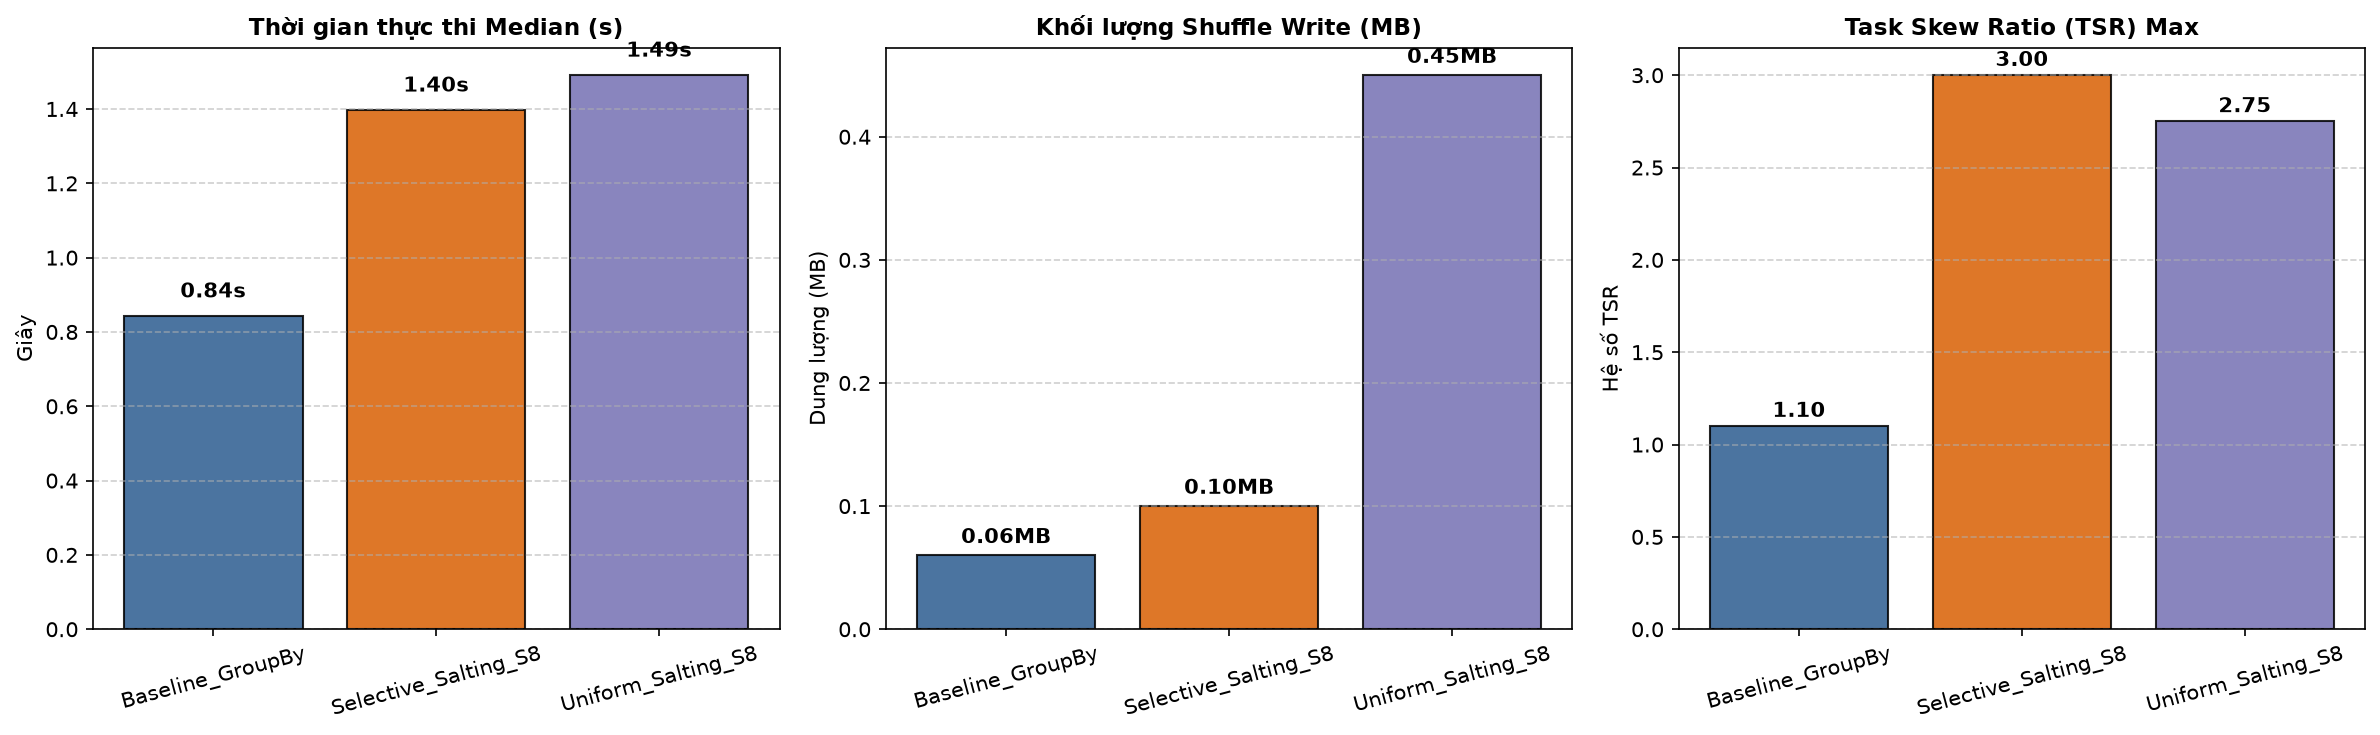

>>> Đã lưu biểu đồ tổng hợp tại: /home/kedora/SEM5/Bigdata/taxi-data-baker-/data/benchmarks/figure_nd2_aggregation_benchmark.png


In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150)

methods_order = df_summary["Phương án"].tolist()
colors = ["#2b5c8f", "#d95f02", "#7570b3"]

# 1. Thời gian thực thi Median
axes[0].bar(df_summary["Phương án"], df_summary["Thời gian Median (s)"], color=colors, edgecolor="black", alpha=0.85)
axes[0].set_title("Thời gian thực thi Median (s)", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Giây")
axes[0].grid(axis="y", linestyle="--", alpha=0.6)
for i, v in enumerate(df_summary["Thời gian Median (s)"]):
    axes[0].text(i, v + 0.05, f"{v:.2f}s", ha="center", fontweight="bold")

# 2. Khối lượng Shuffle Write
axes[1].bar(df_summary["Phương án"], df_summary["Shuffle Write Median (MB)"], color=colors, edgecolor="black", alpha=0.85)
axes[1].set_title("Khối lượng Shuffle Write (MB)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Dung lượng (MB)")
axes[1].grid(axis="y", linestyle="--", alpha=0.6)
for i, v in enumerate(df_summary["Shuffle Write Median (MB)"]):
    axes[1].text(i, v + 0.01, f"{v:.2f}MB", ha="center", fontweight="bold")

# 3. Task Skew Ratio (TSR)
tsr_vals = [float(x) if x != "N/A" else 0.0 for x in df_summary["TSR Max Median"]]
axes[2].bar(df_summary["Phương án"], tsr_vals, color=colors, edgecolor="black", alpha=0.85)
axes[2].set_title("Task Skew Ratio (TSR) Max", fontsize=11, fontweight="bold")
axes[2].set_ylabel("Hệ số TSR")
axes[2].grid(axis="y", linestyle="--", alpha=0.6)
for i, v in enumerate(tsr_vals):
    axes[2].text(i, v + 0.05, f"{v:.2f}", ha="center", fontweight="bold")

for ax in axes:
    ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plot_path = os.path.join(paths["benchmarks_dir"], "figure_nd2_aggregation_benchmark.png")
plt.savefig(plot_path)
plt.show()
print(f">>> Đã lưu biểu đồ tổng hợp tại: {plot_path}")


## 11. Kết luận Khoa học & Đóng góp Báo cáo (Chương 4, Mục 4.2)

### 1. Bản chất Kỹ thuật của Phép gom nhóm (Aggregation Skew):
- Trong Apache Spark, toán tử `groupBy()` tự động được Catalyst tối ưu bằng cơ chế **Map-side Combine** (`HashAggregate` giai đoạn partial).
- Bởi vì không gian khóa `PULocationID` tại NYC chỉ có 261 vùng hợp lệ ($K = 261$), mỗi Map Task (tương ứng với partition đọc vào) đã gom cụm ~5 triệu dòng dữ liệu thô về **tối đa 261 dòng** trước khi phát tán qua mạng Shuffle Exchange.
- Do đó, khối lượng dữ liệu thực tế phải Shuffle trong phép toán Baseline là cực kỳ nhỏ (chỉ vài trăm Kilobytes).

### 2. Chi phí Bổ sung (Overhead) của Kỹ thuật Salting trong Phép gom nhóm:
1. **Phức tạp hóa kế hoạch thực thi (Two-Stage Aggregation):** Salting buộc Spark phải tạo 2 giai đoạn gom nhóm liên tiếp, làm tăng số lượng Stage và chi phí điều phối của DAGScheduler.
2. **Khuếch đại kích thước Shuffle trung gian:** Việc chia $S = 8$ bucket làm tăng số lượng khóa trung gian tại Stage 1 lên gấp 8 lần ($261 \\times 8 = 2,088$ nhóm), làm tăng khối lượng dữ liệu ghi Shuffle thay vì giảm bớt.
3. **Chi phí tính toán CPU:** Việc thực thi hàm băm và gán cột Salt tạo ra phụ phí CPU trên toàn bộ 19.99 triệu dòng.

### 3. Kết luận Thực nghiệm:
> [!IMPORTANT]
> **Kết luận cốt lõi cho Đề tài:** Kỹ thuật Salting **không mang lại lợi ích hiệu năng** trong các bài toán gom nhóm đơn giản có tập khóa đích nhỏ ($K \\ll \\text{Partition Size}$) nhờ sức mạnh của Map-side Combine bản địa trong Spark. Salting chỉ thực sự phát huy tối đa giá trị kỹ thuật trong các phép **Join Skew** (Nội dung 3) - nơi mà Map-side combine không thể áp dụng được.
